# Repeated trials Analysis
> The main aim of this notebook is to <b>remove repeated punished trials</b> from each session and to <b>calculate session performance accurately</b>. \
> <u>Apply filtering</u>: \
    - Exclude repeated Punish trials, except for the first Punish in each consecutive sequence. \
    - Exclude the Reward trial immediately following a sequence of repeated Punish trials.

In [3]:
import datajoint as dj
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os

dj.config["enable_python_native_blobs"] = True
dj.config['database.host'] = 'database.eflab.org:3306'

schemata = {
    'exp'   : 'lab_experiments',
    'beh'   : 'lab_behavior',
}

# create a virtual module for every database schema that you are going to use
for schema, value in schemata.items():
    globals()[schema] = dj.create_virtual_module(schema, value, create_tables=True, create_schema=True)

Please enter DataJoint username:  eflab
Please enter DataJoint password:  ········


[2026-10-13 22:22:59,383][INFO]: Connecting eflab@database.eflab.org:3306
[2026-10-13 22:22:59,410][INFO]: Connected eflab@database.eflab.org:3306


In [4]:
animal_id = 484
difficulty = 1

In [5]:
key_animal = {'animal_id': animal_id, }

session_ids = (
    (
        exp.Session() 
        & key_animal
    ) - exp.Session.Excluded()
).fetch('session')

print('sessions:', session_ids)

sessions: [ 2  4  7  9 10 11 13 15 17 20 21 22 24 25 28 29 30 31 32 33 35]


In [6]:
# Sessions to exclude manually
excluded_sessions = []

In [7]:
results = []
sessions_without_difficulty = []

for session in session_ids:

    # Skip manually excluded sessions
    if session in excluded_sessions:
        continue

    key_animal_session = {
        "animal_id": animal_id,
        "session": session
    }

    diff = (
        exp.Condition.MatchPort()
        * exp.Trial()
        & f"difficulty={difficulty}"
        & key_animal_session
    ).proj("difficulty")

    # Skip session if it has no trials at the selected difficulty
    if len(diff) == 0:
        sessions_without_difficulty.append(session)
        continue

    # Fetch Reward/Punish trials for this session and difficulty
    df = pd.DataFrame(
        (
            exp.Trial.StateOnset()
            * diff
            & 'state IN ("Reward", "Punish")'
        ).fetch(as_dict=True)
    )

    # calculated performance including repeated trials
    rewards = (df["state"] == "Reward").sum()
    punishs = (df["state"] == "Punish").sum()
    
    rep_perf = rewards / (rewards + punishs)
    

    # Identify Punish trials
    is_punish = df["state"] == "Punish"

    # Identify the first Punish in each consecutive Punish sequence
    first_punish = (
        is_punish
        & ~is_punish.shift(1, fill_value=False)
    )

    # Identify Punish trials that are repeated
    repeated_punish = (
        is_punish
        & is_punish.shift(1, fill_value=False)
    )

    # Identify a Reward immediately following a repeated Punish
    reward_after_repeated_punish = (
        (df["state"] == "Reward")
        & repeated_punish.shift(1, fill_value=False)
    )

    # Keep:
    #   - all Reward trials except those immediately after
    #     repeated Punishments
    #   - only the first Punish in each consecutive Punish sequence
    keep = (
        (
            (df["state"] == "Reward")
            & ~reward_after_repeated_punish
        )
        | first_punish
    )

    df = df[keep]

    # Count remaining states for this session
    n_reward = (df["state"] == "Reward").sum()
    n_punish = (df["state"] == "Punish").sum()

    # Calculate performance
    n_trials = n_reward + n_punish

    performance = (
        n_reward / n_trials
        if n_trials > 0
        else np.nan
    )

    results.append({
        "animal_id": animal_id,
        "session": session,
        "n_reward": n_reward,
        "n_punish": n_punish,
        "performance": round(performance, 2),
        "rep_perf":round(rep_perf,2)
    })

results_df = pd.DataFrame(results)

print(
    f"Sessions without difficulty {difficulty}: "
    f"{sessions_without_difficulty}"
)

results_df

Sessions without difficulty 1: [2, 4, 7]


,animal_id,session,n_reward,n_punish,performance,rep_perf
0,484,9,102,74,0.58,0.49
1,484,10,102,74,0.58,0.43
2,484,11,103,74,0.58,0.48
3,484,13,81,67,0.55,0.47
4,484,15,139,91,0.60,0.49
5,484,17,155,95,0.62,0.50
6,484,20,154,97,0.61,0.52
7,484,21,155,107,0.59,0.51
8,484,22,159,102,0.61,0.54
9,484,24,167,95,0.64,0.56


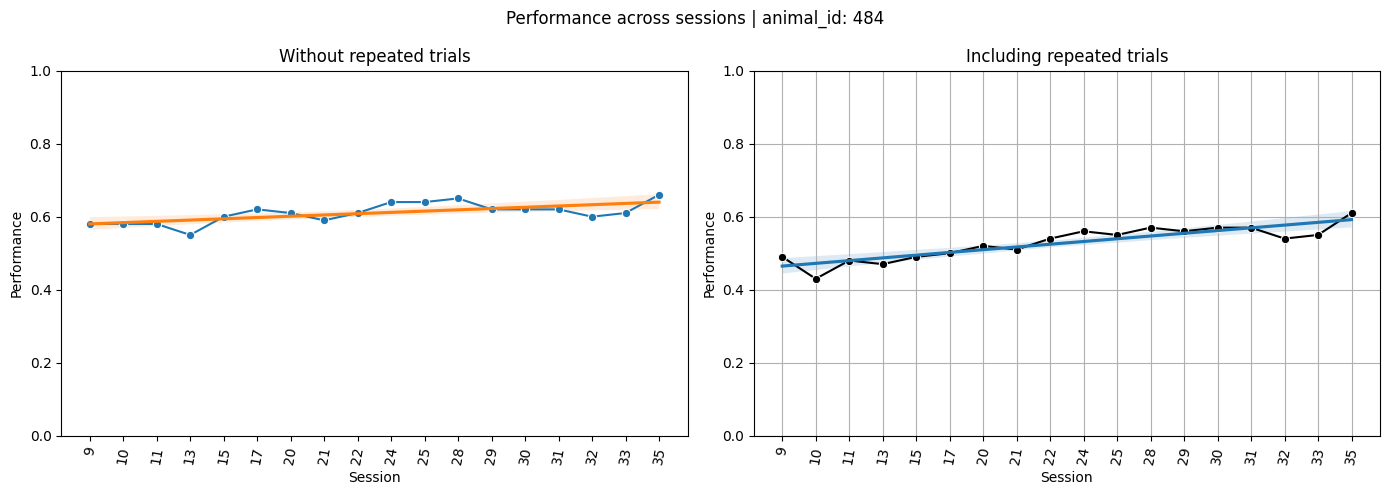

In [8]:
results_df = results_df.sort_values("session")

x = np.arange(len(results_df))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# -----------------------------
# Plot 1: Without repeated trials
# -----------------------------
sns.lineplot(
    x=x,
    y=results_df["performance"],
    marker="o",
    ax=axes[0],
)

sns.regplot(
    x=x,
    y=results_df["performance"],
    scatter=False,
    ax=axes[0],
)

axes[0].set_xticks(x)
axes[0].set_xticklabels(results_df["session"], rotation=80)
axes[0].set_xlabel("Session")
axes[0].set_ylabel("Performance")
axes[0].set_title("Without repeated trials")

# -----------------------------
# Plot 2: Including repeated trials
# -----------------------------
sns.lineplot(
    x=x,
    y=results_df["rep_perf"],
    marker="o",
    color="black",
    ax=axes[1],
)

sns.regplot(
    x=x,
    y=results_df["rep_perf"],
    scatter=False,
    ax=axes[1],
)

axes[1].set_xticks(x)
axes[1].set_xticklabels(results_df["session"], rotation=80)
axes[1].set_xlabel("Session")
axes[1].set_ylabel("Performance")
axes[1].set_title("Including repeated trials")
axes[1].grid()

for ax in axes:
    ax.set_ylim(0, 1)
    ax.set_yticks(np.arange(0, 1.01, 0.2))

fig.suptitle(
    f"Performance across sessions | animal_id: {animal_id}"
)

plt.tight_layout()
plt.show()